<a href="https://colab.research.google.com/github/MatthewPena2/AI-vs-Real-Image-Analyzer/blob/KNN/EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os # used to store kaggle credentials
from google.colab import userdata # obtains API key and account username stored in google colab

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# Very quick check to ensure the cell executed the lines above
print("Kaggle credentials obtained successfully!")

Kaggle credentials obtained successfully!


In [3]:
# Install Kaggle and download CIFAKE
# Install kaggle library
!pip install -q kaggle

# Download CIFAKE using the full dataset path
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images

# Unzip the .zip file where the dataset is stored
# "*.zip" allows us to unzip the dataset file without specifying a name
!unzip -q "*.zip" -d cifake_data

# Very quick check to ensure the cell executed the lines above
# There should be a popup showing the files have been downloaded
print("Dataset download and unzip was successful!")

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 171MB/s] 

Dataset download and unzip was successful!


In [4]:
import torch # import PyTortch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ------Preprocessing------
# Define image transformations for EfficientNet-B0
# This model expects 224x224 input image sizes and standard ImageNet normalization)
transform = transforms.Compose([
    transforms.Resize((224, 224)), # Resizes CIFAKE's small 32 x 32 image size to fit EfficientNet-B0 requirements
    transforms.RandomHorizontalFlip(p=0.5), # Lightweight data augmentation - prevents overfitting
    transforms.ToTensor(), # Loaded Python pixel values are stored as ints; PyTorch models require floating-point tensors
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalizes an iamge to match ImageNet's basic color scales
])

# Directory Paths
train_dir = 'cifake_data/train'
test_dir = 'cifake_data/test'

# Load Datasets using ImageLoader - maps folder names to class labels
train_dataset = datasets.ImageFolder(root=train_dir, transform=transform)
test_dataset = datasets.ImageFolder(root=test_dir, transform=transform)

# Create DataLoaders for batching during training/testing
# Uses deep learning standard batch size of 32
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

# Quick check to ensure program executed to this point
print(f"Dataset pipeline succesfully initiated")
print(f"Classes found: {train_dataset.classes}") # Check to see if PyTorch succesfully scanned folders
print(f"Total training batches: {len(train_loader)}") # Check to see training batch size
print(f"Total test batches: {len(test_loader)}") # Check to see test batch size

# ~83.33% Training : ~16.67% Test
# With a batch size of 32, 3,125 batches = 100,000 training images
# With a batch size of 32, 625 batches = 20,000 test images
# This split matches the standard CIFAKE test/training split

Dataset pipeline succesfully initiated
Classes found: ['FAKE', 'REAL']
Total training batches: 3125
Total test batches: 625


In [5]:
import torch
import torch.nn as nn # for loss function
import torch.optim as optim # for optimizer

#import EfficientNet-B0 from PyTorch Hub
from torchvision import models
from torchvision.models import EfficientNet_B0_Weights

# Device Setup - Check to see if T4 GPU is in use
# CUDA is the hardware-accelerated NVIDIA GPU (provided to Google Colab for free)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
  print(f"GPU Model: {torch.cuda.get_device_name(0)}")

# Load pre-trained EfficientNet-B0 weights for transfer learning
# EfficientNet-B0 was pre-trained on ImageNet, which contains millions of everyday photos
# The model can already extract fundamental visual features (edges, curves, shapes, textures, etc.)
# It CANNOT distinguish between AI and authentic images: that is our job to do
WEIGHTS = EfficientNet_B0_Weights.DEFAULT
myModel = models.efficientnet_b0(weights=WEIGHTS)

# EfficientNet's default classifier is a sequential block ending in a linear layer with 1000 ouputs
# Replace it with a single linear layer mapping to two outputs: 'FAKE' or 'REAL' (from Cell 3)
in_features = myModel.classifier[1].in_features
myModel.classifier[1] = nn.Linear(in_features, 2)

# Map the model to the GPU device
myModel = myModel.to(device)

# Define the loss function - cross-entropy for Logisitc Regression
# Define the optimizer, where:
# 1. learning rate = 0.001 (default for AdamW in PyTorch)
# 2. weight_decay = 0.0001 (custom value: default for AdamW in Pytorch is too strict)
loss_fn = nn.CrossEntropyLoss()
modelOptimizer = optim.AdamW(myModel.parameters(), lr=1e-3, weight_decay=1e-4)

# Quick check to show the model was successfully initialized and move to GPU
print("Model was succesfully initialized and moved to GPU")
print(myModel.classifier)

Using device: cuda
GPU Model: Tesla T4
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s]


Model was succesfully initialized and moved to GPU
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [ ]:
import torch

# Training Loop
# Training and Evaluation Hyperparameters
num_epochs = 5 # starting with an initial value of 5 - may be changed if needed

# Tracking metrics - training/test loss and accuracy stored in a dictionary of lists
metricHistory = {
    'train_loss': [],
    'train_acc': [],
    'test_loss': [],
    'test_acc': []
}

# -------- Training Phase --------
# Notify start
print(f"Starting training for {num_epochs} epochs on device: {device}\n")

# Loop over each epoch
for epoch in range(num_epochs):
  myModel.train() # set the model to training mode
  running_loss = 0.0
  correct_train = 0.0
  total_train = 0.0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    # Zero out the gradients from the previous step
    modelOptimizer.zero_grad()

    # Forward pass: compute predicted outputs by passing inputs to the model
    outputs = myModel(images)

    # Calculate loss
    loss = loss_fn(outputs, labels)

    # Backward pass: compute gradient of the loss with respect to model parameters
    loss.backward()

    # Update the model parameters (weights)
    modelOptimizer.step()

    # Track training loss and accuracy
    running_loss += loss.item() * images.size(0)
    _, predicted = outputs.max(1)
    total_train += labels.size(0)
    correct_train += predicted.eq(labels).sum().item()

    # End of loop

  # Calculate training loss and accuracy
  epoch_train_loss = running_loss / total_train
  epoch_train_acc = correct_train / total_train

  # -------- Testing Phase --------
  myModel.eval() # set the model to evaluation (test) mode
  test_loss = 0.0
  correct_test = 0
  total_test = 0

  # Disable gradient calculation during testing to save memory and speed up computations
  with torch.no_grad():
    for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)

      outputs = myModel(images)
      loss = loss_fn(outputs, labels)

      # Track test loss and accuracy
      test_loss += loss.item() * images.size(0)
      _, predicted = outputs.max(1)
      total_test += labels.size(0)
      correct_test += predicted.eq(labels).sum().item()

      # End of for loop
  # End of with statement

  # Calculate testing loss and accuracy
  epoch_test_loss = test_loss / total_test
  epoch_test_acc = correct_test / total_test

  # Save history
  metricHistory['train_loss'].append(epoch_train_loss)
  metricHistory['train_acc'].append(epoch_train_acc)
  metricHistory['test_loss'].append(epoch_test_loss)
  metricHistory['test_acc'].append(epoch_test_acc)

  # Print progress for each epoch
  print(f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {epoch_train_loss:.4f} | Train Accuracy: {epoch_train_acc*100:.2f}% | "
        f"Test Loss: {epoch_test_loss:.4f} | Test Accuracy: {epoch_test_acc*100:.2f}%")

# End of for loop
print("\nTraining Complete.")


Starting training for 5 epochs on device: cuda

Epoch [1/5] | Train Loss: 0.1494 | Train Accuracy: 94.25% | Test Loss: 0.0859 | Test Accuracy: 96.67%
Epoch [2/5] | Train Loss: 0.1013 | Train Accuracy: 96.21% | Test Loss: 0.0862 | Test Accuracy: 96.80%
Epoch [3/5] | Train Loss: 0.0846 | Train Accuracy: 96.81% | Test Loss: 0.0689 | Test Accuracy: 97.52%
Epoch [4/5] | Train Loss: 0.0720 | Train Accuracy: 97.30% | Test Loss: 0.0682 | Test Accuracy: 97.64%
Epoch [5/5] | Train Loss: 0.0622 | Train Accuracy: 97.60% | Test Loss: 0.0871 | Test Accuracy: 96.68%

Training Complete.


In [ ]:
# TODO: Save the best model to Google Drive, then download that file path
# It could be manually saved, but once the runtime disconnects, it will be lost alongside the other data
# Save it to Google Drive so it exists even after runtime disconnects

In [6]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# Temporarily strip the final classifier layer to extract the 1280 feature embeddings
feature_extractor = torch.nn.Sequential(*list(myModel.children())[:-1])
feature_extractor.eval()

def extract_features(dataloader, sample_limit=2000):
    features = []
    labels = []
    total_extracted = 0

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            # Forward pass through feature extractor
            feats = feature_extractor(images)
            # Flatten spatial dimensions (EfficientNet-B0 outputs [batch, 1280, 1, 1] after pooling)
            feats = torch.flatten(feats, start_dim=1)

            features.append(feats.cpu().numpy())
            labels.append(targets.numpy())

            total_extracted += images.size(0)
            if total_extracted >= sample_limit:
                break

    return np.concatenate(features)[:sample_limit], np.concatenate(labels)[:sample_limit]

# Extract features from Train and Test sets
X_train, y_train = extract_features(train_loader, sample_limit=2000)
X_test, y_test = extract_features(test_loader, sample_limit=500)

print(f"Extracted Train features shape: {X_train.shape}")
print(f"Extracted Test features shape: {X_test.shape}")

Extracted Train features shape: (2000, 1280)
Extracted Test features shape: (500, 1280)


In [7]:
# Initialize and train the K-Nearest Neighbors Model
# 9 nearest neighbors appeared to give the best accuracy for test data.
knn_model = KNeighborsClassifier(n_neighbors=9, metric='cosine')
knn_model.fit(X_train, y_train)

# Evaluate the model
y_pred = knn_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"KNN Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=train_dataset.classes))

KNN Model Accuracy: 89.20%

Classification Report:
              precision    recall  f1-score   support

        FAKE       1.00      0.89      0.94       500
        REAL       0.00      0.00      0.00         0

    accuracy                           0.89       500
   macro avg       0.50      0.45      0.47       500
weighted avg       1.00      0.89      0.94       500



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Neighbors:  1 | Train Acc: 100.00% | Test Acc: 83.80%
Neighbors:  3 | Train Acc: 91.50% | Test Acc: 87.40%
Neighbors:  5 | Train Acc: 88.95% | Test Acc: 88.80%
Neighbors:  7 | Train Acc: 87.55% | Test Acc: 88.40%
Neighbors:  9 | Train Acc: 86.95% | Test Acc: 89.20%
Neighbors: 11 | Train Acc: 86.25% | Test Acc: 89.40%
Neighbors: 13 | Train Acc: 85.85% | Test Acc: 88.60%
Neighbors: 15 | Train Acc: 85.80% | Test Acc: 88.20%


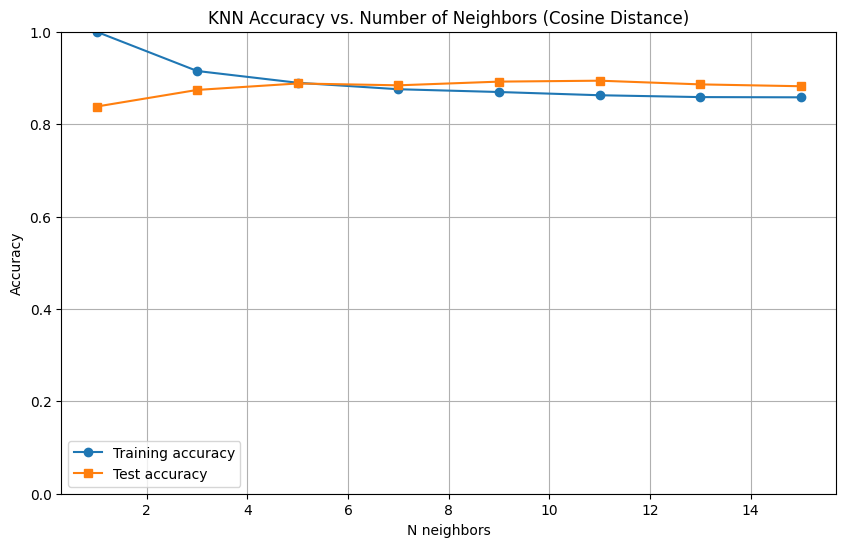

In [8]:
import matplotlib.pyplot as plt

# Define the range of n_neighbors to test, 9 appears to preform best for the test data.
neighbors_settings = [1, 3, 5, 7, 9, 11, 13, 15]
train_accuracies = []
test_accuracies = []

for n_neighbors in neighbors_settings:
    # Initialize and fit model
    knn = KNeighborsClassifier(n_neighbors=n_neighbors, metric='cosine')
    knn.fit(X_train, y_train)

    # Record training accuracy
    train_acc = knn.score(X_train, y_train)
    train_accuracies.append(train_acc)

    # Record test accuracy
    test_acc = knn.score(X_test, y_test)
    test_accuracies.append(test_acc)

    print(f"Neighbors: {n_neighbors:2d} | Train Acc: {train_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")

# Plot the results with customized y-axis scale
plt.figure(figsize=(10, 6))
plt.plot(neighbors_settings, train_accuracies, label="Training accuracy", marker='o')
plt.plot(neighbors_settings, test_accuracies, label="Test accuracy", marker='s')
plt.ylabel("Accuracy")
plt.xlabel("N neighbors")
plt.title("KNN Accuracy vs. Number of Neighbors (Cosine Distance)")
plt.ylim(0.0, 1.0)
plt.grid(True)
plt.legend()
plt.show()